# Tarea 06: Tres masas acopladas — entregable del Módulo 1

**Semana 6** · Entrega: antes de la clase de la Semana 7

Esta tarea es además el **entregable del Módulo 1**: pesa más que una tarea
semanal y se evalúa también la documentación y el historial de commits. Léela
completa antes de empezar y revisa el checklist de [`README.md`](README.md).

## Objetivos de la tarea

1. Plantear un sistema de osciladores acoplados en forma matricial y resolver
   su problema de eigenvalores de forma simbólica.
2. Construir la solución temporal como superposición de modos normales y
   verificarla sustituyéndola de vuelta.
3. Graficar el resultado con `lambdify` y Matplotlib, y reportarlo con
   `sp.latex`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

sp.init_printing()

## El sistema

Tres masas iguales $m$ sobre una mesa sin fricción, en línea, unidas entre sí y
a las dos paredes por **cuatro** resortes iguales de constante $k$:

```
pared —/\/\— m₁ —/\/\— m₂ —/\/\— m₃ —/\/\— pared
```

Si $x_1$, $x_2$ y $x_3$ son los desplazamientos respecto al equilibrio, la
segunda ley aplicada a cada masa da $M\ddot{\mathbf{x}} = -K\mathbf{x}$ con

$$K = k\begin{pmatrix} 2 & -1 & 0 \\ -1 & 2 & -1 \\ 0 & -1 & 2 \end{pmatrix},
\qquad M = m\,\mathbb{1}_3$$

Es el sistema de la clase con una masa más. Todo lo que necesitas está en los
dos notebooks de la semana 6; lo que cambia es que ahora hay **tres**
frecuencias y **tres** modos.

## Ejercicio 1: el planteamiento matricial

Completa la celda con estos nombres exactos, que son los que usa
`tests/test_tarea.py`:

- `tiempo`, `masa`, `constante` y `amplitud`: los cuatro símbolos. Sus
  **nombres de símbolo** deben ser `"t"`, `"m"`, `"k"` y `"A"` (no los de las
  variables de Python). `tiempo` es real; los otros tres son **positivos** —
  una masa, una constante elástica y una amplitud no son negativas, y decirlo
  le ahorra a SymPy considerar ramas que la física descarta.
- `rigidez`: la matriz $K$ de arriba, como `sp.Matrix` de 3×3.
- `masas`: la matriz $M$, con `sp.eye(3)`.

Comprueba tú mismo, antes de seguir, que `rigidez.is_symmetric()` es `True`.
Si no lo es, hay un signo mal puesto.

In [2]:
# TODO: completa el ejercicio 1
#Primero, definimos los símbolos

tiempo =sp.Symbol("t", real=True)
masa =sp.Symbol("m", positive=True)
constante =sp.Symbol("k", positive=True)
amplitud =sp.Symbol("A", positive=True)

#Ahora, definimos a la matriz K
rigidez =constante*sp.Matrix([[2, -1, 0], [-1, 2, -1], [0, -1, 2]])

#Después, definimos a M
masas =sp.eye(3)

In [3]:
#Imprimimos los símbolos
print(tiempo)
print(masa)
print(constante)
print(amplitud)

t
m
k
A


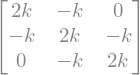

In [4]:
#Verificamos cómo se ve la matriz
display(rigidez)

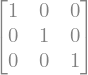

In [5]:
#Verificamos cómo se ve la matriz m
display(masas)

In [6]:
#comprobamos si rigidez es simétrica
rigidez.is_symmetric()

True

## Ejercicio 2: frecuencias y modos normales

Buscando soluciones de la forma $\mathbf{x}(t) = \mathbf{v}\cos(\omega t)$, el
problema se vuelve algebraico:

$$K\mathbf{v} = \omega^2 M\mathbf{v}$$

Es el eigenproblema de $M^{-1}K$, con $\lambda = \omega^2$.

- `frecuencias`: una **lista de tres** expresiones, las $\omega = \sqrt{\lambda}$.
- `modos`: una **lista de tres** vectores columna (`sp.Matrix` de 3×1), en el
  **mismo orden** que `frecuencias` — el modo `modos[i]` debe corresponder a
  `frecuencias[i]`. Los tests verifican esa correspondencia, no el orden en que
  decidas ponerlos.

Sugerencia: recorre `(masas.inv() * rigidez).eigenvects()` con un `for` y arma
las dos listas de una vez, como en la sesión 1. Cada elemento es una tupla
`(eigenvalor, multiplicidad, [vectores])`.

Una advertencia que vale puntos: **no ordenes las frecuencias con
`sorted(..., key=sp.default_sort_key)` creyendo que salen de menor a mayor**.
Ese orden es alfabético-estructural, no numérico, y aquí no coinciden. Si
quieres ordenarlas por tamaño, sustituye valores numéricos y ordena por eso.

In [7]:
# TODO: completa el ejercicio 2
#Como vamos a realizar este ejercicio haciendo un ciclo for, vamos a definir a frecuencias
#y modos como listas vacías

frecuencias =[]
modos =[]

m1=masas.inv()*rigidez

#En esta primera línea, obtenemos la tupla que contiene: el valor propio, la multiplicidad y los vectores propios 
for valor, _, vectores in m1.eigenvects():   
    #En esta segunda, entramos a la lista de los vectores propios y los guardamos en modos
    for vector in vectores:
        omega=sp.sqrt(valor)
        frecuencias.append(omega)
        modos.append(vector)


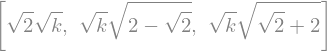

In [8]:
#Comprobamos las salidas
frecuencias

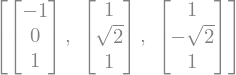

In [9]:
modos

## Ejercicio 3: la evolución temporal

La solución general es la superposición de los tres modos,

$$\mathbf{x}(t) = \sum_{i=1}^{3} c_i\, \mathbf{v}_i \cos(\omega_i t)$$

y aquí ya está impuesto que las tres masas parten **del reposo** (no hay senos).
Falta la otra condición inicial: **jalamos solo la primera masa** hasta
$A$ y soltamos, o sea $\mathbf{x}(0) = (A, 0, 0)$.

- `coeficientes`: el diccionario `{c1: ..., c2: ..., c3: ...}` que sale de
  resolver $\mathbf{x}(0) = (A, 0, 0)$ con `sp.solve`. Declara tú los tres
  símbolos $c_i$.
- `movimiento`: el vector columna 3×1 con los coeficientes ya sustituidos y
  simplificado.

Verifica antes de seguir —esto no lo hace el autograding por ti, pero sí lo
verifica— que el residuo $M\ddot{\mathbf{x}} + K\mathbf{x}$ es la matriz cero.
Si no lo es, el error está en el ejercicio 2.

Todo debe quedar **exacto**: nada de `0.5` ni `1.4142`. Un flotante suelto
contamina la expresión entera, y hay un test que lo detecta.

In [10]:
# TODO: completa el ejercicio 3
#primero, definimos nuestros símbolos
t=sp.Symbol("t")
c1, c2, c3=sp.symbols("c1:4")
A=sp.Symbol("A")

#Definimos ahora nuestra ecuación x(t)
eq1=c1*modos[0]*sp.cos(frecuencias[0]*t)+c2*modos[1]*sp.cos(frecuencias[1]*t)+c3*modos[2]*sp.cos(frecuencias[2]*t)
condicion_inicial = sp.Eq(eq1.subs(t, 0), sp.Matrix([A, 0, 0]))

#Resolvemos ahora, para obtener la lista de los coeficientes:
coeficientes =sp.solve(condicion_inicial, (c1, c2, c3))

#definimos el movimiento
movimiento =sp.simplify(eq1.subs(coeficientes))

In [11]:
t

In [12]:
c1, c2, c3

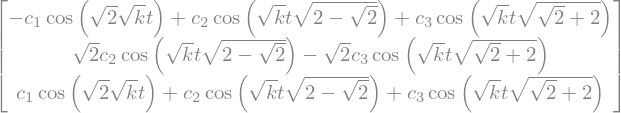

In [13]:
eq1

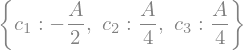

In [14]:
coeficientes

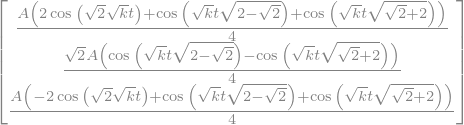

In [15]:
movimiento

## Ejercicio 4: la gráfica y el reporte

Ahora los números. Con `numeros = {constante: 1, masa: 1, amplitud: 1}`:

- Sustituye y convierte cada componente de `movimiento` en una función numérica
  con `sp.lambdify(tiempo, ..., "numpy")`.
- Grafica las tres masas contra el tiempo, de $t = 0$ a $t = 40$, en una sola
  figura creada con `fig, ax = plt.subplots()` — el nombre exacto importa,
  porque los tests lo leen. Cada curva con su `label`, y la figura con
  `ax.set_xlabel`, `ax.set_ylabel`, `ax.set_title` y `ax.legend()`.
- `reporte`: una cadena de f-string con las tres frecuencias insertadas por
  `sp.latex`, mostrada con `display(Markdown(reporte))`. Recuerda duplicar las
  llaves de LaTeX (`{{`, `}}`) dentro de la f-string.

In [ ]:
# TODO: completa el ejercicio 4
from IPython.display import Markdown

numeros = {constante: 1, masa: 1, amplitud: 1}
f=[sp.lambdify(tiempo, componente.subs(numeros), "numpy")
     for componente in movimiento]

tiempo1=np.linspace(0, 40, 500)

# Crea la figura con  fig, ax = plt.subplots()  y grafica las tres masas.
#Vamos a hacer la gráfica
fig, ax=plt.subplots()
ax.plot(tiempo1, f)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
#reporte = ...

In [18]:
#Comprobamos cómo se ve la función lambdify que llamé f
print(f)

<function _lambdifygenerated at 0x7833ceec9e80>


## Discusión

_Contesta aquí, en dos o tres párrafos. Esta parte no la califica el
autograding: la revisa el asistente._

1. Describe con palabras cómo se mueven las tres masas en cada uno de los tres
   modos normales, leyendo los vectores que obtuviste. ¿Cuál es el más lento y
   por qué tiene sentido que lo sea?
2. En uno de los modos la masa de en medio **no se mueve**. Identifícalo y
   explica por qué su frecuencia sale exactamente $\sqrt{2k/m}$, sin hacer la
   cuenta completa.
3. Mirando tu gráfica: ¿la masa 3 se mueve desde el primer instante o tarda en
   arrancar? ¿Cómo se ve en la gráfica que la energía viaja por la cadena?

_(Escribe tu respuesta aquí.)_

## Resumen

Entrega esta tarea por **Pull Request dentro de tu fork**, como las anteriores.
El paso a paso está en [`docs/git-guia.md`](../../docs/git-guia.md), y el
checklist completo en [`README.md`](README.md).

Como es el entregable del módulo, se evalúa también **cómo** llegaste: haz un
commit por ejercicio conforme avances, con mensajes que digan qué hiciste. Un
único commit gigante la noche anterior cuesta puntos aunque el notebook esté
perfecto.

Antes de entregar, corre el notebook desde un kernel limpio
(`Kernel → Restart & Run All`) y confirma que llega hasta el final sin errores.
Al hacer push, GitHub Actions corre los tests y deja un check ✅ o ❌ en tu
Pull Request.